# Практическое занятие № 17 — DBSCAN и агломеративная кластеризация
**ТюмГУ · «Технологии искусственного интеллекта — 1» · 90 минут**

Цель: понять ограничения K-means, освоить DBSCAN (ядро / граница / шум) и четыре типа связи в иерархической кластеризации. Параметры выбираются **без целевых меток**. `late` и `actual_minutes` запрещены для кластеризации заказов. Синтетические иллюстрации не являются доказательством качества на реальных данных.

**Материалы:** `orders_dirty.csv` из занятий 3–16 или `demo_orders_17_18.csv` только для проверки запуска. Загружайте файлы в рабочую папку Colab. Все вычисления reproducible при `random_state=42`.

## 1. Ручной пример: ядровая, граничная и шумовая точки (0–15 мин)
DBSCAN использует окрестность $N_\varepsilon(x)=\{x_j:d(x,x_j)\leq\varepsilon\}$, включая саму точку. Ядровая точка: $|N_\varepsilon(x)|\geq MinPts$. Граничная точка достижима из ядра, но сама не является ядром. Шум имеет метку `-1`.

При `eps=0.45`, `min_samples=4` разберите точки B, P и Q вручную (расстояние евклидово).

Python: 3.12.14 ; scikit-learn: 1.9.1
Ручной расчёт расстояний и окрестностей (eps=0.45; точка входит в окрестность):
point                    nearest_4_other         N_eps  count_including_self
    B A:0.300, D:0.300, C:0.424, P:0.427 A, B, C, D, P                     5
    P B:0.427, D:0.427, A:0.716, C:0.716       B, D, P                     3
    Q H:3.960, F:4.104, G:4.104, E:4.243             Q                     1
Типы точек: {'A': 'ядро', 'B': 'ядро', 'C': 'ядро', 'D': 'ядро', 'E': 'ядро', 'F': 'ядро', 'G': 'ядро', 'H': 'ядро', 'P': 'граница', 'Q': 'шум'}
При MinPts=3 точка P: ядро


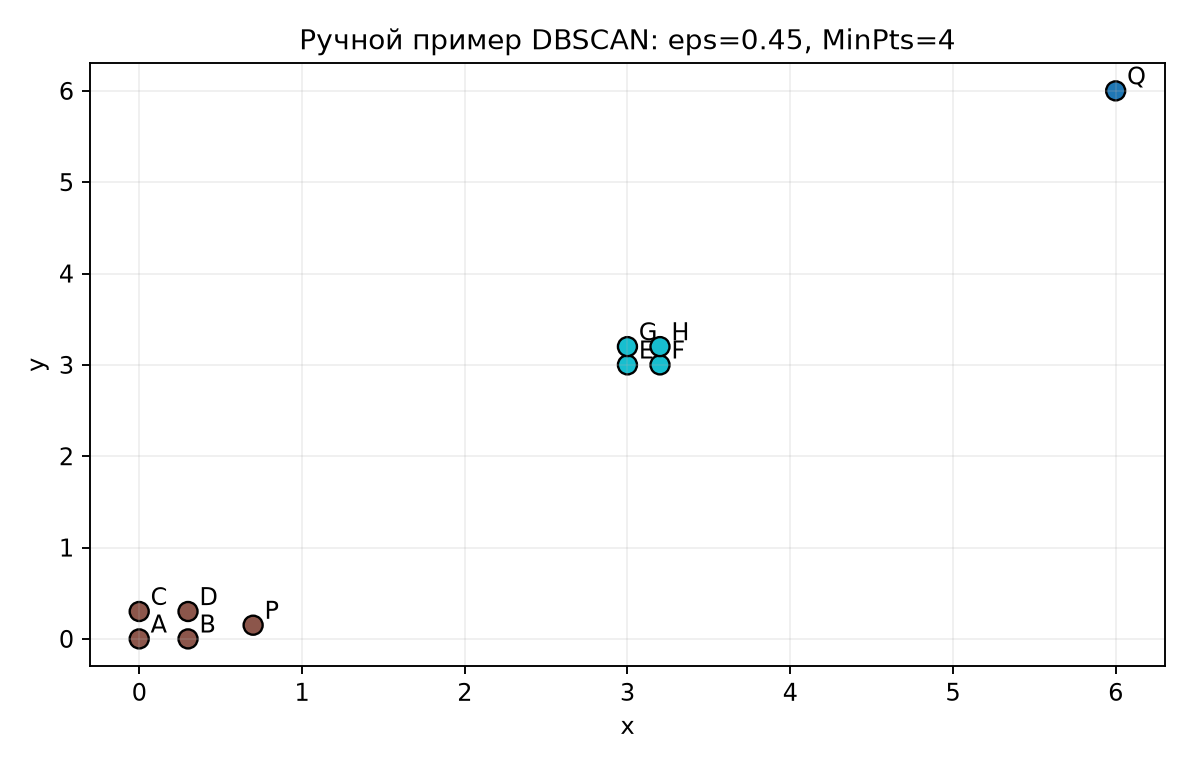

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.datasets import make_moons
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
import sklearn
from IPython.display import display, Image
print('Python:',sys.version.split()[0],'; scikit-learn:',sklearn.__version__)
np.set_printoptions(precision=3,suppress=True)

POINTS={'A':(0,0),'B':(.3,0),'C':(0,.3),'D':(.3,.3),
        'E':(3,3),'F':(3.2,3),'G':(3,3.2),'H':(3.2,3.2),
        'P':(.7,.15),'Q':(6,6)}
names=list(POINTS); xy=np.array(list(POINTS.values()),float)
eps_toy=.45; minpts_toy=4
distances_toy=pd.DataFrame(np.linalg.norm(xy[:,None,:]-xy[None,:,:],axis=2),index=names,columns=names)
neighborhood={n:distances_toy.columns[distances_toy.loc[n]<=eps_toy+1e-12].tolist() for n in names}
manual_rows=[]
for n in ['B','P','Q']:
    neighbors=neighborhood[n]
    manual_rows.append({'point':n,'nearest_4_other':', '.join(f'{x}:{v:.3f}' for x,v in distances_toy.loc[n].drop(n).nsmallest(4).items()),
                        'N_eps':', '.join(neighbors),'count_including_self':len(neighbors)})
manual=pd.DataFrame(manual_rows)
print('Ручной расчёт расстояний и окрестностей (eps=0.45; точка входит в окрестность):')
print(manual.to_string(index=False))
db_toy=DBSCAN(eps=eps_toy,min_samples=minpts_toy).fit(xy)
core_toy={names[i] for i in db_toy.core_sample_indices_}
classification={n:('шум' if lab==-1 else ('ядро' if n in core_toy else 'граница')) for n,lab in zip(names,db_toy.labels_)}
print('Типы точек:',classification)
assert classification['B']=='ядро' and classification['P']=='граница' and classification['Q']=='шум'
db_toy_3=DBSCAN(eps=eps_toy,min_samples=3).fit(xy)
print('При MinPts=3 точка P:', 'ядро' if names.index('P') in db_toy_3.core_sample_indices_ else 'не ядро')
manual.to_csv('17_manual_neighbors.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(7,4.5))
ax.scatter(xy[:,0],xy[:,1],c=db_toy.labels_,cmap='tab10',s=65,edgecolor='black')
for n,(x,y) in POINTS.items(): ax.annotate(n,(x+.07,y+.07))
ax.set(xlabel='x',ylabel='y',title='Ручной пример DBSCAN: eps=0.45, MinPts=4');ax.grid(alpha=.2)
fig.tight_layout();fig.savefig('17_manual_dbscan.png',dpi=170);display(Image(filename='17_manual_dbscan.png'));plt.close(fig)


**Самостоятельно:** объясните, почему P — граница, а не шум. Повторите с `min_samples=3`: как изменится тип P? Не называйте номера кластеров «классами задержки».

## 2. Почему геометрия кластеров важна: две луны (15–30 мин)
На неполусферических группах K-means может разделить данные не по естественным изогнутым структурам. Сравните K-means, DBSCAN и Ward на **одном и том же** искусственном наборе. Для DBSCAN запишите долю шума и число непустых групп.

           method  groups  noise  noise_pct
    K-means (K=2)       2      0        0.0
DBSCAN (eps=0.19)       2     12        4.7
       Ward (K=2)       2      0        0.0

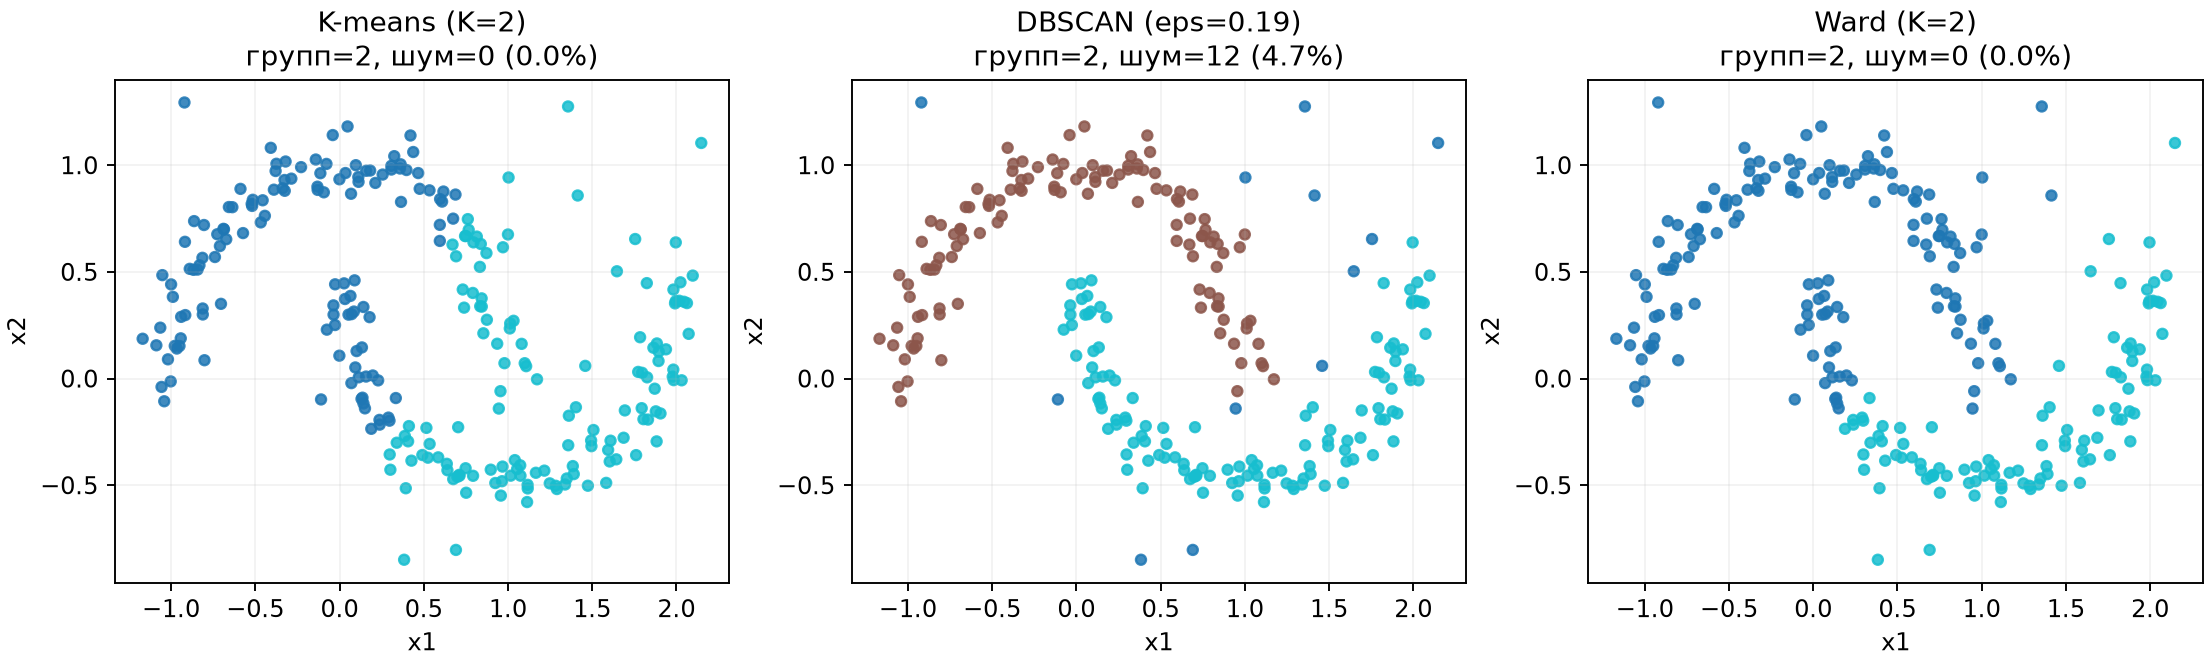

Изогнутые луны и отдельные выбросы показывают различия геометрии; параметры нельзя переносить на заказы.


In [2]:
X_moon,_=make_moons(n_samples=240,noise=.075,random_state=42)
rng=np.random.default_rng(42)
outliers=rng.uniform(low=[-1.25,-.95],high=[2.25,1.35],size=(18,2))
X_shape=np.vstack([X_moon,outliers])
shape_models={
    'K-means (K=2)':KMeans(n_clusters=2,n_init=10,random_state=42).fit_predict(X_shape),
    'DBSCAN (eps=0.19)':DBSCAN(eps=.19,min_samples=5).fit_predict(X_shape),
    'Ward (K=2)':AgglomerativeClustering(n_clusters=2,linkage='ward').fit_predict(X_shape)
}
shape_rows=[]
fig,axs=plt.subplots(1,3,figsize=(13,3.9),constrained_layout=True)
for ax,(name,labs) in zip(axs,shape_models.items()):
    groups=len(set(labs)-{-1}); noise=int(np.sum(labs==-1))
    shape_rows.append({'method':name,'groups':groups,'noise':noise,'noise_pct':100*noise/len(labs)})
    colors=np.where(labs==-1,-1,labs)
    ax.scatter(X_shape[:,0],X_shape[:,1],c=colors,cmap='tab10',s=18,alpha=.85)
    ax.set_title(f'{name}\nгрупп={groups}, шум={noise} ({100*noise/len(labs):.1f}%)')
    ax.set(xlabel='x1',ylabel='x2');ax.grid(alpha=.15)
shape_summary=pd.DataFrame(shape_rows)
print(shape_summary.round(1).to_string(index=False))
fig.savefig('17_moons_comparison.png',dpi=170);display(Image(filename='17_moons_comparison.png'));plt.close(fig)
print('Изогнутые луны и отдельные выбросы показывают различия геометрии; параметры нельзя переносить на заказы.')


## 3. Подготовка заказов и защита от утечки (30–43 мин)
Работаем с тремя доступными при оформлении признаками. Сортируем по `created_at`, 80% ранних заказов — `dev` для выбора настроек. Последние 20% — `holdout`, который **не участвует в подборе `eps` и числа групп**. Заполнение пропусков и стандартизация обучаются только на `dev`. `order_id` нужен для аудита, `late` и `actual_minutes` — лишь для внешнего последующего анализа, не для кластеризации.

In [3]:
source=Path('orders_dirty.csv')
assert source.exists(),'Для основной работы нужен orders_dirty.csv из предыдущих практик'
assert Path('data_dictionary.csv').exists(),'Нужен словарь data_dictionary.csv'
raw=pd.read_csv(source,encoding='utf-8-sig')
FEATURES=['distance_km','queue_size','promised_minutes']
required={'order_id','created_at',*FEATURES}
assert required.issubset(raw.columns),f'Нет столбцов: {required-set(raw.columns)}'
print('Основной источник:',source.name,'; размер N×p:',raw.shape)
print('Все исходные поля и типы:\n',raw.dtypes.to_string())
print('Исходные пропуски:\n',raw.isna().sum().to_string())
full_dupes=int(raw.duplicated().sum());id_dupes_raw=int(raw.order_id.duplicated().sum())
invalid_id=int(raw.order_id.isna().sum());invalid_date=int(pd.to_datetime(raw.created_at,errors='coerce').isna().sum())
print('Полные повторы:',full_dupes,'; повторы ID в исходнике:',id_dupes_raw,'; пустые ID:',invalid_id,'; неверные даты:',invalid_date)
audit=[]
for _,row in raw.loc[raw.duplicated()].iterrows():
    audit.append({'order_id':row.order_id,'field':'full_row','original':'повтор всей строки','action':'удалён полный дубликат'})
df=raw.drop_duplicates().copy()
print('После удаления полных повторов: повторы ID:',int(df.order_id.duplicated().sum()))
for _,row in df.loc[df.distance_km.astype(str).str.contains(',',regex=False)].iterrows():
    audit.append({'order_id':row.order_id,'field':'distance_km','original':row.distance_km,
                  'action':'десятичная запятая заменена точкой; значение сохранено'})
for _,row in df.loc[df.queue_size.isna()].iterrows():
    audit.append({'order_id':row.order_id,'field':'queue_size','original':'пусто',
                  'action':'NaN; медиана dev после разделения'})
assert df.order_id.notna().all() and df.order_id.is_unique,'Неразрешённая аномалия order_id: требуется разбор исходных записей'
df['created_at']=pd.to_datetime(df.created_at,errors='coerce')
assert df.created_at.notna().all(),'Неразрешённая аномалия created_at: требуется разбор исходных записей'
for col in FEATURES:
    before=int(df[col].isna().sum())
    original=df[col].copy()
    normalized=df[col].astype(str).str.replace(',','.',regex=False) if col=='distance_km' else df[col]
    df[col]=pd.to_numeric(normalized,errors='coerce').replace([np.inf,-np.inf],np.nan)
    df.loc[df[col]<0,col]=np.nan
    if col=='promised_minutes':df.loc[df[col]<=0,col]=np.nan
    for idx in df.index[df[col].isna() & original.notna()]:
        audit.append({'order_id':df.loc[idx,'order_id'],'field':col,'original':str(original.loc[idx]),
                      'action':'непригодная запись → NaN; медиана dev после разделения'})
    print(col,': пропуски до',before,', после приведения и проверки диапазона',int(df[col].isna().sum()))
cleaning_audit=pd.DataFrame(audit)
print('Исходная запись и действие очистки:\n',cleaning_audit.to_string(index=False))
cleaning_audit.to_csv('17_cleaning_audit.csv',index=False,encoding='utf-8-sig')
df=df.sort_values(['created_at','order_id'],kind='stable').reset_index(drop=True)
assert {'order_id','late','actual_minutes'}.isdisjoint(FEATURES)
cut=int(len(df)*.8)
dev=df.iloc[:cut].copy();holdout=df.iloc[cut:].copy()
assert len(dev)>=20 and len(holdout)>=5
assert set(dev.order_id).isdisjoint(set(holdout.order_id))
assert dev.created_at.max()<=holdout.created_at.min()
imp=SimpleImputer(strategy='median',keep_empty_features=True)
scale=StandardScaler()
Z_dev=scale.fit_transform(imp.fit_transform(dev[FEATURES]))
Z_holdout=scale.transform(imp.transform(holdout[FEATURES]))
assert np.isfinite(Z_dev).all() and np.isfinite(Z_holdout).all()
assert np.allclose(Z_dev.mean(axis=0),0,atol=1e-10)
print('После очистки:',len(df),'; dev:',len(dev),'; holdout:',len(holdout))
print('Дата dev до:',dev.created_at.max(),'; holdout от:',holdout.created_at.min())
print('В X:',FEATURES,'; исключены ID, late, actual_minutes и остальные поля')
scaler_table=pd.DataFrame({'feature':FEATURES,'imputer_median':imp.statistics_,
                           'dev_mean':scale.mean_,'dev_scale':scale.scale_})
print('Параметры только dev:\n',scaler_table.round(3).to_string(index=False))
scaler_table.to_csv('17_scaler_parameters.csv',index=False,encoding='utf-8-sig')


Основной источник: orders_dirty.csv ; размер N×p: (600, 10)
Все исходные поля и типы:
 order_id                str
created_at              str
distance_km             str
queue_size          float64
weather                 str
zone                    str
promised_minutes      int64
actual_minutes        int64
late                  int64
vehicle_type            str
Исходные пропуски:
 order_id            0
created_at          0
distance_km         0
queue_size          1
weather             1
zone                0
promised_minutes    0
actual_minutes      0
late                0
vehicle_type        0
Полные повторы: 1 ; повторы ID в исходнике: 1 ; пустые ID: 0 ; неверные даты: 0
После удаления полных повторов: повторы ID: 0
distance_km : пропуски до 0 , после приведения и проверки диапазона 1
queue_size : пропуски до 1 , после приведения и проверки диапазона 1
promised_minutes : пропуски до 0 , после приведения и проверки диапазона 0
Исходная запись и действие очистки:
 order_id       f

## 4. DBSCAN: k-distance, подбор eps и ограничение Silhouette (43–63 мин)
Для `min_samples=5` построим расстояние до **пятого соседа, считая саму точку**. Резкий перегиб кривой подсказывает кандидатов `eps`, но не определяет оптимум автоматически. В таблице фиксируем число групп, число/долю шума и Silhouette **только по непризнанным шумом объектам** при наличии хотя бы 2 кластеров. Не сравнивайте этот Silhouette напрямую с оценкой метода без отбрасывания шума.

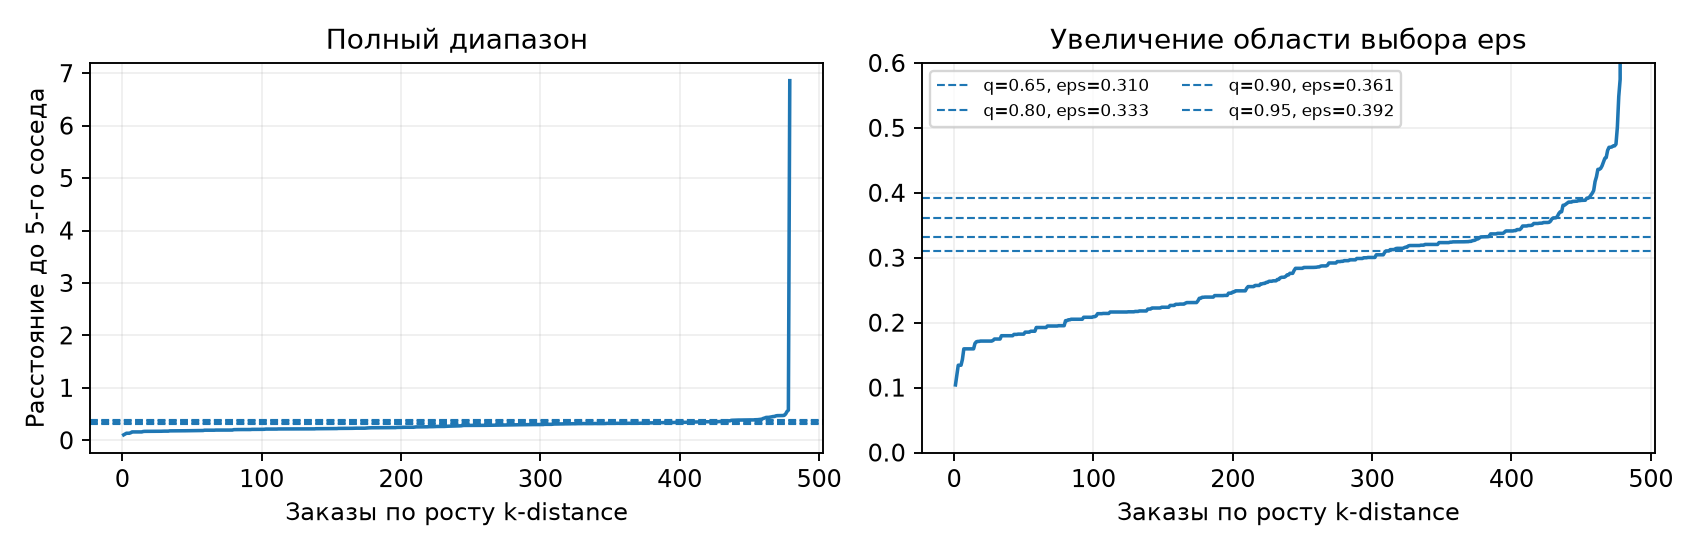

DBSCAN, MinPts=5; Silhouette только без шума:
  quantile    eps  clusters  noise  noise_pct  silhouette_excl_noise
     0.65 0.3105        14     62    12.9436                -0.0669
     0.80 0.3326         6     18     3.7578                 0.0762
     0.90 0.3614         3      9     1.8789                 0.1306
     0.95 0.3918         1      3     0.6263                    NaN
Выбран eps только по dev: 0.3614 ; группы/шум: (3, 9, 1.8789144050104385)
Профили DBSCAN, включая шум -1 (средние в исходных единицах):
  cluster   n  distance_km  queue_size  promised_minutes
      -1   9        19.57       12.00             69.67
       0 442         8.46        9.63             49.08
       1  23        16.87       18.70             77.00
       2   5        17.54        1.00             63.20


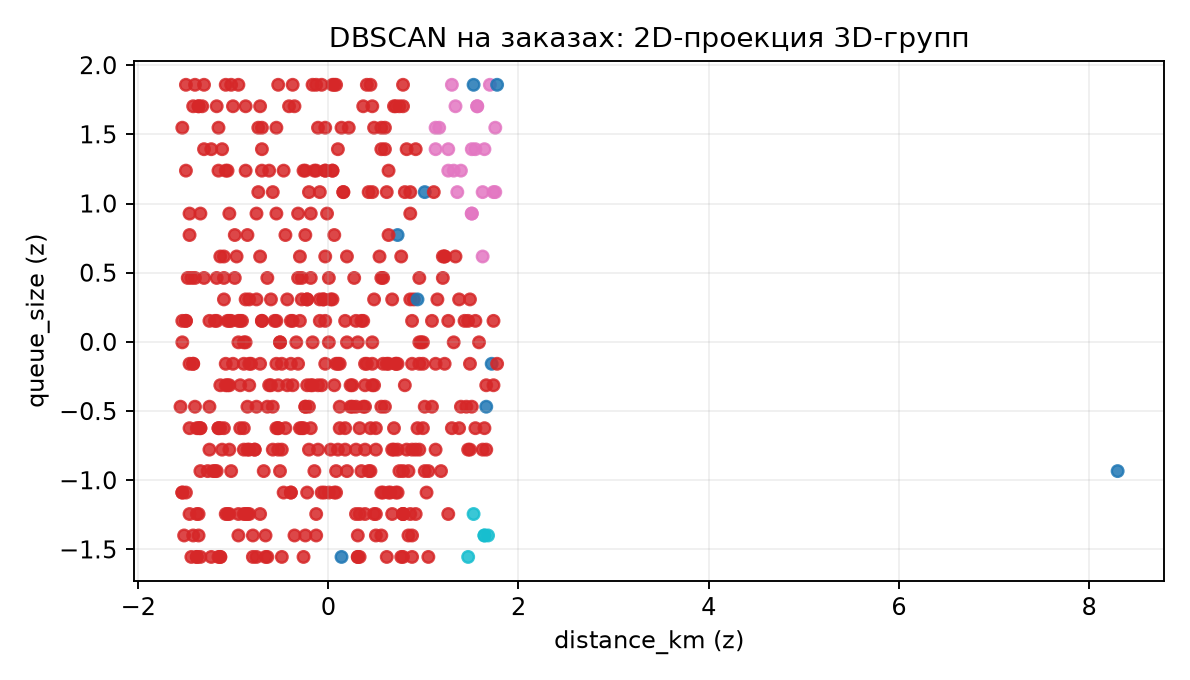

In [4]:
min_samples=5
knn=NearestNeighbors(n_neighbors=min_samples).fit(Z_dev)
kdist=np.sort(knn.kneighbors(Z_dev)[0][:,-1])
quantiles=[.65,.80,.90,.95]
eps_candidates=np.round(np.quantile(kdist,quantiles),4)
assert len(set(eps_candidates))==4,'Квантили дали повторяющиеся eps: пересмотрите точность и кандидатов'
fig,axs=plt.subplots(1,2,figsize=(10,3.25),sharex=True)
for ax in axs:
    ax.plot(np.arange(len(kdist))+1,kdist)
    for q,eps in zip(quantiles,eps_candidates):
        ax.axhline(eps,ls='--',lw=.9,label=f'q={q:.2f}, eps={eps:.3f}')
    ax.set_xlabel('Заказы по росту k-distance');ax.grid(alpha=.2)
axs[0].set(title='Полный диапазон',ylabel='Расстояние до 5-го соседа')
axs[1].set(title='Увеличение области выбора eps',ylim=(0,max(.6,float(np.quantile(kdist,.98))*1.15)))
axs[1].legend(ncol=2,fontsize=7,loc='upper left')
fig.tight_layout();fig.savefig('17_k_distance.png',dpi=170);display(Image(filename='17_k_distance.png'));plt.close(fig)

def dbscan_metrics(X,labels):
    non_noise=labels!=-1
    ncl=len(set(labels)-{-1})
    nnoise=int((~non_noise).sum())
    sil=np.nan
    if ncl>=2 and non_noise.sum()>ncl:
        sil=float(silhouette_score(X[non_noise],labels[non_noise]))
    return ncl,nnoise,100*nnoise/len(labels),sil

rows=[];candidates={}
for q,eps in zip(quantiles,eps_candidates):
    model=DBSCAN(eps=float(eps),min_samples=min_samples).fit(Z_dev)
    candidates[float(eps)]=model
    groups,noise,noise_pct,sil=dbscan_metrics(Z_dev,model.labels_)
    rows.append({'quantile':q,'eps':float(eps),'clusters':groups,'noise':noise,'noise_pct':noise_pct,'silhouette_excl_noise':sil})
results_db=pd.DataFrame(rows)
print('DBSCAN, MinPts=5; Silhouette только без шума:\n',results_db.round(4).to_string(index=False))
feasible=results_db[(results_db.clusters>=2)&(results_db.noise_pct<=35)&np.isfinite(results_db.silhouette_excl_noise)]
if len(feasible):
    chosen_eps=float(feasible.sort_values(['silhouette_excl_noise','noise_pct'],ascending=[False,True]).iloc[0].eps)
else:
    chosen_eps=float(eps_candidates[2]);print('Кандидат с >=2 группами и <=35% шума не найден; выбран q=.90 с явной оговоркой.')
chosen_db=candidates[chosen_eps]
print('Выбран eps только по dev:',chosen_eps,'; группы/шум:',dbscan_metrics(Z_dev,chosen_db.labels_)[:3])
db_profiles=dev[FEATURES].copy()
db_profiles[FEATURES]=imp.transform(dev[FEATURES])
db_profiles['cluster']=chosen_db.labels_
db_profiles=db_profiles.groupby('cluster').agg(n=('cluster','size'),distance_km=('distance_km','mean'),
                                               queue_size=('queue_size','mean'),promised_minutes=('promised_minutes','mean')).reset_index()
print('Профили DBSCAN, включая шум -1 (средние в исходных единицах):\n',db_profiles.round(2).to_string(index=False))
db_profiles.to_csv('17_dbscan_profiles.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(Z_dev[:,0],Z_dev[:,1],c=chosen_db.labels_,cmap='tab10',s=24,alpha=.85)
ax.set(xlabel='distance_km (z)',ylabel='queue_size (z)',title='DBSCAN на заказах: 2D-проекция 3D-групп')
ax.grid(alpha=.2)
fig.tight_layout();fig.savefig('17_orders_dbscan.png',dpi=170);display(Image(filename='17_orders_dbscan.png'));plt.close(fig)


**Практическое исследование:** измените `min_samples` на 4 и 8, опишите, как изменились шум и число групп. Если шумовых объектов много, не объявляйте Silhouette «лучшим качеством» без оценки покрытия.

## 5. Иерархическая кластеризация и дендрограмма (63–80 мин)
Сравните `single`, `complete`, `average`, `ward` при одинаковом `K=3`. Ward минимизирует прирост внутрикластерной суммы квадратов; дендрограмма показывает порядок и высоту слияний. В отличие от DBSCAN, `AgglomerativeClustering` не имеет штатного `predict` для новых заказов.

Четыре linkage на одном dev, K=3:
  linkage  clusters  min_size  max_size  silhouette
  single         3         1       477      0.0497
complete         3         1       291      0.3728
 average         3         1       250      0.3631
    ward         3       129       191      0.3209
Профили Ward, исходные единицы:
  cluster   n  distance_km  queue_size  promised_minutes
       0 159         3.66        9.23             35.80
       1 191        11.04        6.48             52.96
       2 129        13.19       16.25             66.66


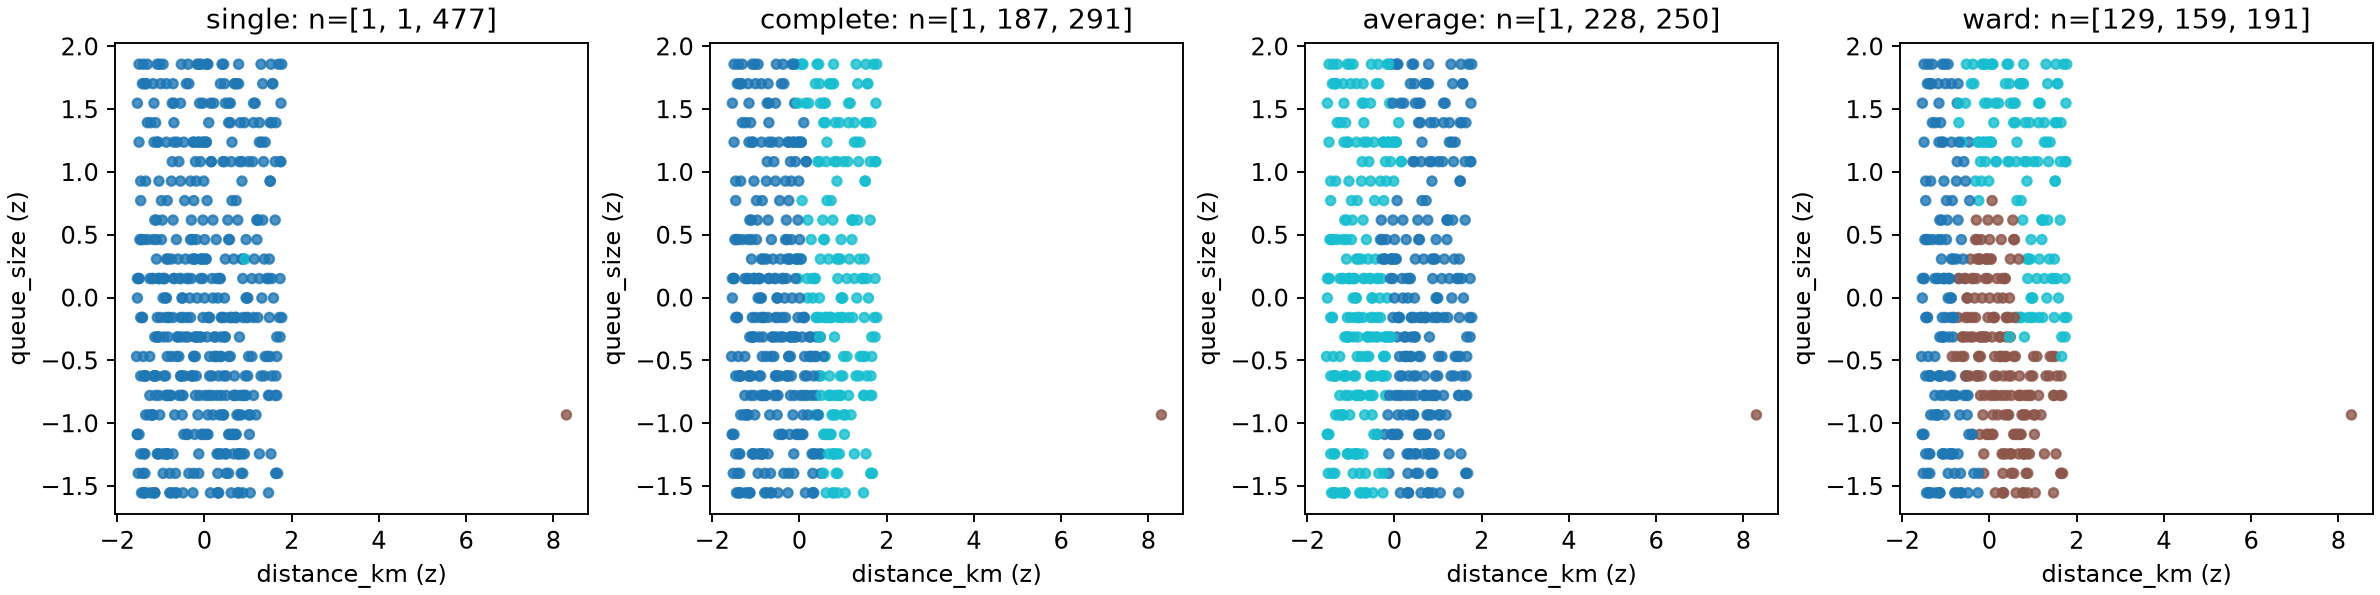

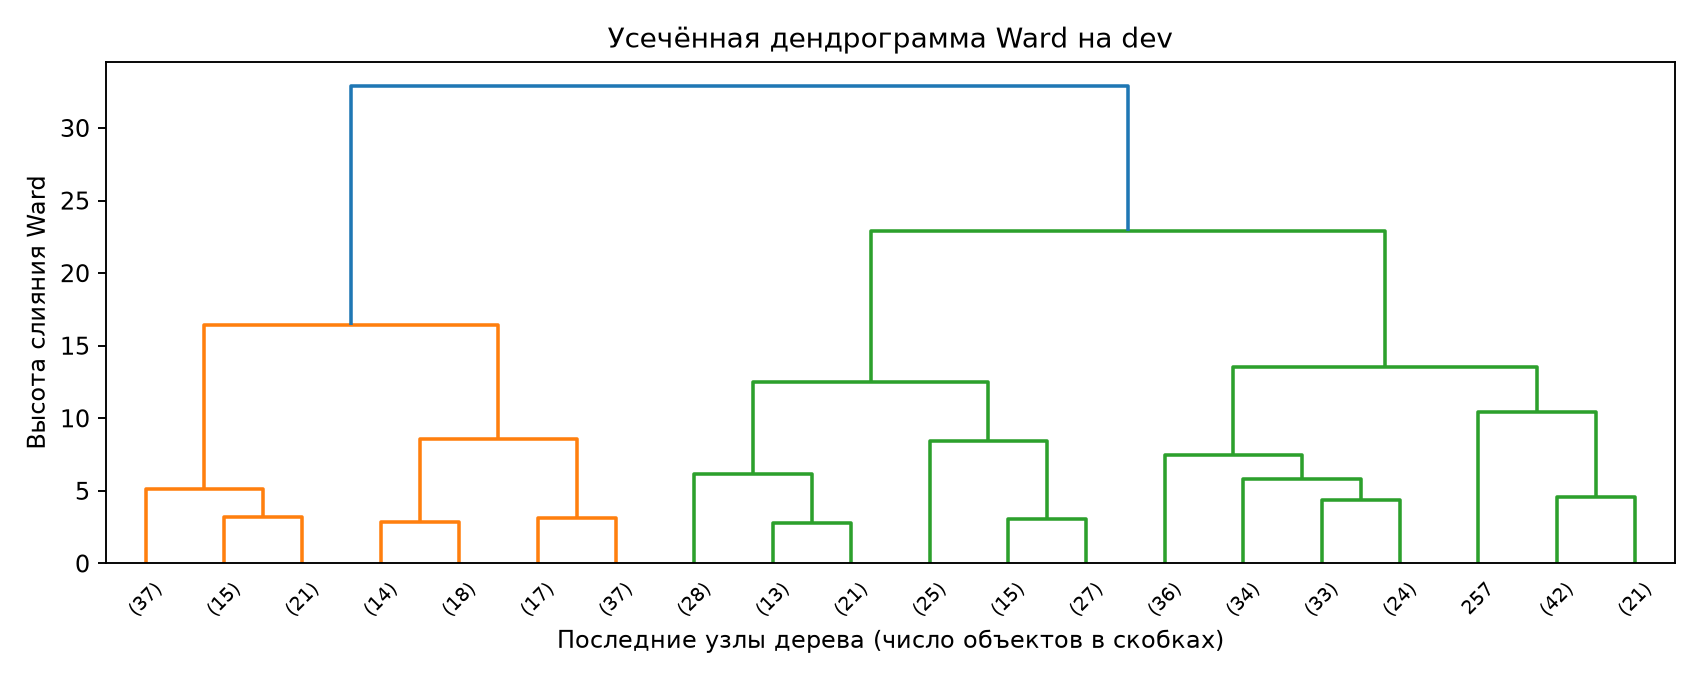

K-means vs Ward при K=3: ARI = 0.5305
У Ward высоты показывают цену/расстояние слияния по его критерию; сравнивать высоты разных linkage напрямую нельзя.


In [5]:
K=3
rows_h=[];hier_labels={}
fig,axs=plt.subplots(1,4,figsize=(14,3.5),constrained_layout=True)
for ax,method in zip(axs,['single','complete','average','ward']):
    labs=AgglomerativeClustering(n_clusters=K,linkage=method).fit_predict(Z_dev)
    hier_labels[method]=labs
    counts=np.bincount(labs)
    sil=float(silhouette_score(Z_dev,labs))
    rows_h.append({'linkage':method,'clusters':len(set(labs)),'min_size':int(counts.min()),
                   'max_size':int(counts.max()),'silhouette':sil})
    ax.scatter(Z_dev[:,0],Z_dev[:,1],c=labs,cmap='tab10',s=15,alpha=.8)
    ax.set_title(f'{method}: n={sorted(counts.tolist())}');ax.set(xlabel='distance_km (z)',ylabel='queue_size (z)')
results_h=pd.DataFrame(rows_h)
print('Четыре linkage на одном dev, K=3:\n',results_h.round(4).to_string(index=False))
ward_profiles=dev[FEATURES].copy()
ward_profiles[FEATURES]=imp.transform(dev[FEATURES])
ward_profiles['cluster']=hier_labels['ward']
ward_profiles=ward_profiles.groupby('cluster').agg(n=('cluster','size'),distance_km=('distance_km','mean'),queue_size=('queue_size','mean'),promised_minutes=('promised_minutes','mean')).reset_index()
print('Профили Ward, исходные единицы:\n',ward_profiles.round(2).to_string(index=False))
ward_profiles.to_csv('17_ward_profiles.csv',index=False,encoding='utf-8-sig')
fig.savefig('17_linkage_comparison.png',dpi=170);display(Image(filename='17_linkage_comparison.png'));plt.close(fig)
Z_link=linkage(Z_dev,method='ward')
fig,ax=plt.subplots(figsize=(10,4.0))
dendrogram(Z_link,truncate_mode='lastp',p=min(20,len(dev)-1),show_leaf_counts=True,ax=ax)
ax.set(xlabel='Последние узлы дерева (число объектов в скобках)',ylabel='Высота слияния Ward',title='Усечённая дендрограмма Ward на dev')
plt.xticks(rotation=45,fontsize=8);fig.tight_layout();fig.savefig('17_ward_dendrogram.png',dpi=170);display(Image(filename='17_ward_dendrogram.png'));plt.close(fig)
base=KMeans(n_clusters=K,n_init=10,random_state=42).fit_predict(Z_dev)
print('K-means vs Ward при K=3: ARI =',round(adjusted_rand_score(base,hier_labels['ward']),4))
print('У Ward высоты показывают цену/расстояние слияния по его критерию; сравнивать высоты разных linkage напрямую нельзя.')


## 6. Вывод и ограничения для будущих заказов (80–90 мин)
DBSCAN не имеет обычного `predict`. Ниже показано **приближённое** правило: присвоить метку ближайшей ядровой точки, если расстояние до неё ≤ `eps`, иначе шум. Оно не пересчитывает плотность и не является полноценным DBSCAN на новых данных. Обязательно опишите этот компромисс в отчёте.

In [6]:
# DBSCAN и AgglomerativeClustering не предоставляют обычный predict для новых строк.
# Это приближение к меткам ранее обученного DBSCAN, а не повторный плотностный поиск.
core_idx=chosen_db.core_sample_indices_
if len(core_idx):
    nearest_core=NearestNeighbors(n_neighbors=1).fit(Z_dev[core_idx])
    distances,idx=nearest_core.kneighbors(Z_holdout)
    approx_labels=np.where(distances[:,0]<=chosen_eps,chosen_db.labels_[core_idx[idx[:,0]]],-1)
else:
    approx_labels=np.full(len(holdout),-1,dtype=int)
print('Holdout: условно присвоено групп',len(set(approx_labels)-{-1}),'отмечено шумом',int(np.sum(approx_labels==-1)))
exports=holdout[['order_id','created_at']].copy()
exports['dbscan_nearest_core_approx']=approx_labels
exports.to_csv('17_holdout_approx.csv',index=False,encoding='utf-8-sig')
results_db.to_csv('17_dbscan_metrics.csv',index=False,encoding='utf-8-sig')
results_h.to_csv('17_hierarchical_metrics.csv',index=False,encoding='utf-8-sig')
print('Созданы 17_holdout_approx.csv, 17_dbscan_metrics.csv, 17_hierarchical_metrics.csv')
assert len(exports)==len(holdout) and exports.order_id.is_unique

sens=[]
for m in [4,5,8]:
    labels=DBSCAN(eps=chosen_eps,min_samples=m).fit_predict(Z_dev)
    groups,noise,noise_pct,sil=dbscan_metrics(Z_dev,labels)
    sens.append({'min_samples':m,'eps_fixed':chosen_eps,'clusters':groups,'noise':noise,'noise_pct':noise_pct,'silhouette_excl_noise':sil})
sensitivity=pd.DataFrame(sens)
print('Чувствительность к MinPts при неизменном eps:\n',sensitivity.round(4).to_string(index=False))
sensitivity.to_csv('17_minpts_sensitivity.csv',index=False,encoding='utf-8-sig')


Holdout: условно присвоено групп 3 отмечено шумом 6
Созданы 17_holdout_approx.csv, 17_dbscan_metrics.csv, 17_hierarchical_metrics.csv
Чувствительность к MinPts при неизменном eps:
  min_samples  eps_fixed  clusters  noise  noise_pct  silhouette_excl_noise
           4     0.3614         3      5     1.0438                 0.1350
           5     0.3614         3      9     1.8789                 0.1306
           8     0.3614         5     45     9.3946                 0.1397


### Что сдавать
1. Отчёт 2–4 страницы (без приложений): метод, исходная и рабочая выборки, ручной пример B/P/Q, две таблицы метрик, **k-distance**, дендрограмма, интерпретация 2–3 групп, ограничения/риск утечек.
2. Исполняемый `17_student.ipynb` (Restart & Run All) и по возможности CSV с результатами.
3. **Самостоятельно:** сравните результаты DBSCAN при `min_samples=4,5,8`; объясните, почему разные условия масштабирования изменяют понятие плотности.

**Контроль:** в каких ситуациях K-means, Ward и DBSCAN принципиально расходятся? Что означает `-1`? Почему `silhouette` при высоком шуме может вводить в заблуждение?

## Ответы на самостоятельные вопросы ноутбука

### Ручной пример из раздела 1

При `eps=0.45` окрестность B — `{A, B, C, D, P}`, то есть 5 точек, поэтому B является ядром при `MinPts=4`. Окрестность P — `{B, D, P}`: расстояния до B и D равны примерно 0,427, до A и C — примерно 0,716. P не достигает порога 4, но находится в окрестности ядровых B и D, поэтому является **граничной**, а не шумовой точкой. У Q ближайшая другая точка H на расстоянии примерно 3,960; в её окрестности только Q, поэтому это шум. Если уменьшить `min_samples` до 3 при том же `eps`, P становится **ядровой** точкой. Номера групп не обозначают классы задержки.

### Сравнение методов на двух лунах из раздела 2

На одинаковых 258 искусственных точках K-means и Ward построили по две группы без шума, а DBSCAN — две группы и выделил 12 точек (4,7 %) как шум. На графике видно, что DBSCAN лучше следует изгибу лун; K-means и Ward чаще проводят границу между компактными областями и обязаны отнести выбросы к одной из групп. Это геометрическая иллюстрация, а не подтверждение качества на заказах.

### Исследование `min_samples` из разделов 4 и 6

На одних и тех же стандартизованных 479 заказах при фиксированном `eps=0.3614`:

| MinPts | Групп | Шум, точек | Шум, % | Silhouette без шума |
|---:|---:|---:|---:|---:|
| 4 | 3 | 5 | 1,04 | 0,1350 |
| 5 | 3 | 9 | 1,88 | 0,1306 |
| 8 | 5 | 45 | 9,39 | 0,1397 |

При большем MinPts для ядра нужна более плотная окрестность: шум вырос, а прежние группы частично распались. Silhouette при MinPts=8 немного выше, но рассчитан уже без 45 шумовых заказов; трактовать его как безусловно лучший результат нельзя. Если изменить масштабы признаков, изменятся евклидовы расстояния и состав окрестностей, поэтому `eps` нужно подбирать заново.

### Итог по заказам

Для DBSCAN с `MinPts=5` квантили k-distance дали четыре `eps`: 0,3105; 0,3326; 0,3614; 0,3918. Выбран 0,3614: 3 группы, 9 шумовых точек (1,88 %) и Silhouette без шума 0,1306. Однако размеры групп 442, 23 и 5 показывают, что метод почти не разделил основную массу заказов. При `K=3` Ward дал группы 159, 191 и 129, Silhouette 0,3209 и более содержательные профили: (0) близкие, умеренная очередь, короткий срок около 36 минут; (1) среднее расстояние, малая очередь, срок около 53 минут; (2) дальние, большая очередь, длинный срок около 67 минут. Поэтому для описательной сегментации именно этих заказов выбран Ward; DBSCAN полезен как проверка плотности и поиск нетипичных объектов. `single` создал цепочку из 477 точек и два одиночных кластера, а `complete` и `average` тоже выделили одиночный кластер. В реализации SciPy высота слияния Ward равна корню из удвоенного прироста внутригрупповой суммы квадратов в стандартизованном пространстве; её нельзя сравнивать с высотами другого linkage.

Методы не доказывают причины задержек: `late` и `actual_minutes` исключены. Двумерные графики скрывают третий признак. DBSCAN не имеет обычного `predict`; присвоение holdout по ближайшей ядровой точке — только приближение, а не повторный DBSCAN. Так же штатного `predict` нет у AgglomerativeClustering.
